# Validation and Testing

Experiment notebook for the part counting pipeline, cut down to what I am presenting. It runs the functions in `functions/` on the labeled images in `images/captured_images/` and compares the predicted count to the true count in `images/labels.xlsx`.

1. The pipeline on one image, stage by stage
2. Results with different settings (binary threshold, kernel size, minimum area) on every labeled image
3. Two images in detail: image 156 (an empty scene) and image 29 (15 parts, some of them touching)
4. My functions against OpenCV: are the results the same, and how long do they take

The figures are saved to `images/` so they can go into the presentation and the README.

`autoreload` is on, so edits to the files in `functions/` are picked up without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

from functions.gray_scale import gray_scale_frame, weights
from functions.binary_thresholding import binary_threshold
from functions.morph_close_open import morph_operation, dilate, erode
from functions.counting import count_objects

## Dataset

In [2]:
IMAGE_DIR = Path("images/captured_images")
LABELS_FILE = Path("images/labels.xlsx")
FIGURE_DIR = Path("images")   # Figures for the presentation and the README are saved here

# Row N of labels.xlsx holds the true part count for "image (N).jpg"
true_counts = pd.read_excel(LABELS_FILE, header=None)[0].astype(int).tolist()
image_paths = [IMAGE_DIR / f"image ({number}).jpg" for number in range(1, len(true_counts) + 1)]


def load_image(number):
    path = image_paths[number - 1]
    frame = cv2.imread(str(path))

    if frame is None:
        raise FileNotFoundError(path)

    return frame


print(len(image_paths), "labeled images")

156 labeled images


## 1. The pipeline on one image

`run_pipeline` chains the same four functions the live camera script uses. `show_pipeline` runs it on one labeled image and plots every stage.

In [3]:
def run_pipeline(frame, threshold=200, kernel_size=3, min_area=300):
    gray = gray_scale_frame(frame)
    binary = binary_threshold(gray, threshold)
    cleaned = morph_operation(binary, kernel_size)
    count = count_objects(cleaned, min_area)

    return gray, binary, cleaned, count


def show_pipeline(image_number, threshold=200, kernel_size=3, min_area=300, save=False):
    frame = load_image(image_number)
    gray, binary, cleaned, count = run_pipeline(frame, threshold, kernel_size, min_area)

    views = [cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), gray, binary, cleaned]
    titles = [
        "Original",
        "Grayscale",
        f"Binary threshold ({threshold})",
        f"Closing + opening ({kernel_size}x{kernel_size} kernel)",
    ]

    fig, ax = plt.subplots(2, 2, figsize=(14, 8))

    for a, view, title in zip(ax.flat, views, titles):
        a.imshow(view, cmap="gray", vmin=0, vmax=255)
        a.set_title(title)
        a.axis("off")

    fig.suptitle(
        f"image ({image_number}).jpg   predicted: {count}   true: {true_counts[image_number - 1]}   "
        f"(min_area={min_area})"
    )
    plt.tight_layout()

    if save:
        fig.savefig(FIGURE_DIR / f"pipeline_stages_image_{image_number}.png", dpi=150, bbox_inches="tight")

    plt.show()

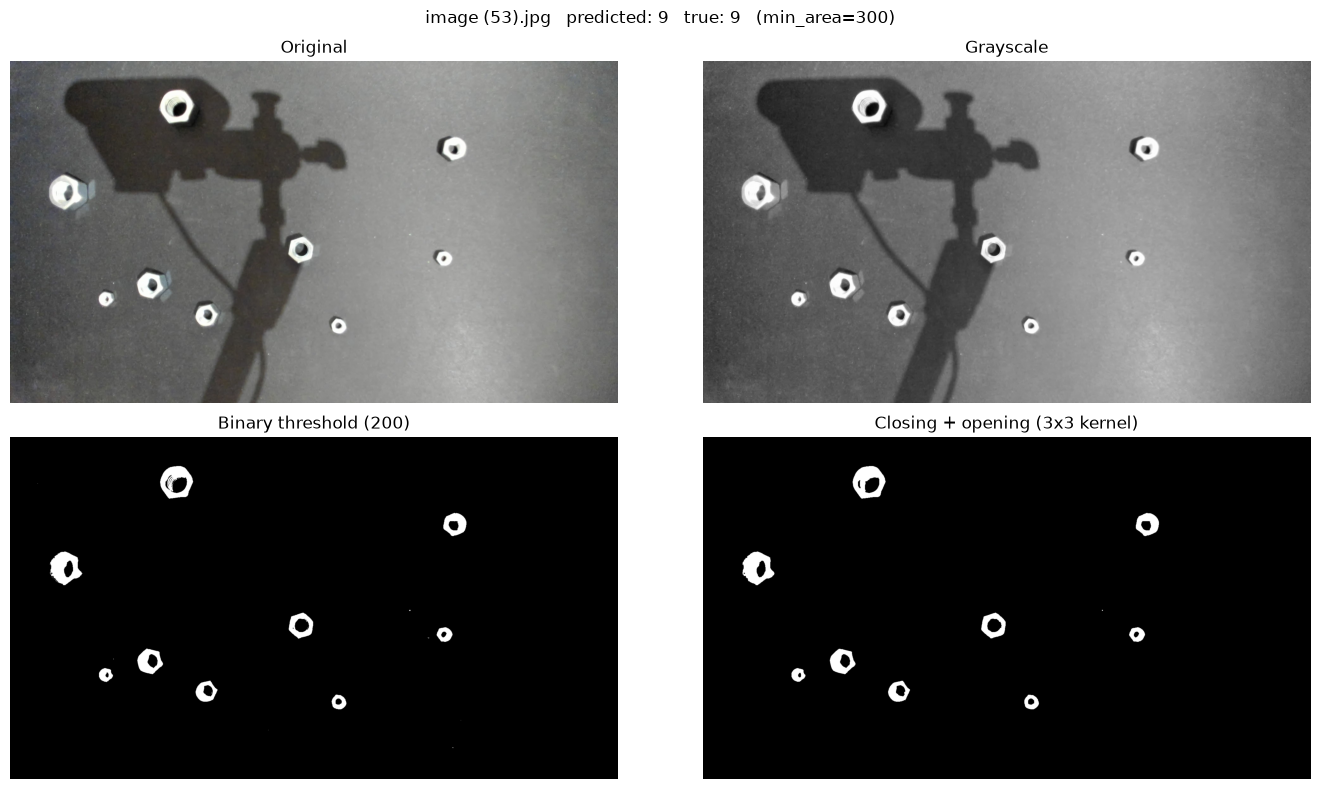

In [4]:
# Image 53 has 9 parts that do not touch. Change these to try one combination of settings on one image.
show_pipeline(image_number=53, threshold=200, kernel_size=3, min_area=300, save=True)

## 2. Results with different settings

Every combination of the values below is run on every labeled image. Edit the lists to try other values. A bigger grid takes longer because each combination runs on all the images (this grid takes about two minutes).

- `THRESHOLDS`: grayscale value a pixel must be above to become white
- `KERNEL_SIZES`: side length of the square kernel for closing + opening (1 = no morphology)
- `MIN_AREAS`: smallest blob, in pixels, that counts as a part

In [5]:
THRESHOLDS = [140, 160, 180, 200, 220, 240]
KERNEL_SIZES = [1, 3, 5, 7, 9]
MIN_AREAS = [100, 300, 1000, 3000]

rows = []

for number, true_count in enumerate(true_counts, start=1):
    gray = gray_scale_frame(load_image(number))

    for threshold in THRESHOLDS:
        binary = binary_threshold(gray, threshold)

        for kernel_size in KERNEL_SIZES:
            cleaned = morph_operation(binary, kernel_size)

            for min_area in MIN_AREAS:
                rows.append({
                    "image": number,
                    "threshold": threshold,
                    "kernel_size": kernel_size,
                    "min_area": min_area,
                    "true": true_count,
                    "predicted": count_objects(cleaned, min_area),
                })

# One row per image per combination of settings
results = pd.DataFrame(rows)
results["error"] = results["predicted"] - results["true"]

print(len(results), "runs")
results.head()

18720 runs


,image,threshold,kernel_size,min_area,true,predicted,error
0,1,140,1,100,18,38,20
1,1,140,1,300,18,10,-8
2,1,140,1,1000,18,5,-13
3,1,140,1,3000,18,3,-15
4,1,140,3,100,18,37,19


### Which settings work

One row per combination of settings, best first:

- `exact_accuracy`: share of images where the predicted count equals the true count
- `mean_abs_error`: how many parts the count is off by on average
- `mean_error`: positive means it overcounts, negative means it undercounts

In [6]:
SETTINGS = ["threshold", "kernel_size", "min_area"]

summary = (
    results.assign(exact=results["error"] == 0, abs_error=results["error"].abs())
    .groupby(SETTINGS)
    .agg(
        exact_accuracy=("exact", "mean"),
        mean_abs_error=("abs_error", "mean"),
        mean_error=("error", "mean"),
    )
    .reset_index()
    .sort_values(["exact_accuracy", "mean_abs_error"], ascending=[False, True])
    .reset_index(drop=True)
)

best_threshold, best_kernel_size, best_min_area = summary.loc[0, SETTINGS].tolist()

print(f"Best: threshold={best_threshold}, kernel_size={best_kernel_size}, min_area={best_min_area}")
print("Top 5 settings")
summary.head(5)

Best: threshold=200, kernel_size=1, min_area=300
Top 5 settings


,threshold,kernel_size,min_area,exact_accuracy,mean_abs_error,mean_error
0,200,1,300,0.775641,0.262821,-0.070513
1,200,1,100,0.724359,0.365385,0.032051
2,200,1,1000,0.698718,0.378205,-0.365385
3,220,5,300,0.698718,0.423077,-0.230769
4,200,3,1000,0.685897,0.532051,-0.532051


In [7]:
print("Bottom 5 settings")
summary.tail(5)

Bottom 5 settings


,threshold,kernel_size,min_area,exact_accuracy,mean_abs_error,mean_error
115,140,3,100,0.0,19.948718,19.948718
116,140,1,100,0.0,20.307692,20.307692
117,160,1,100,0.0,21.006410,21.006410
118,160,3,100,0.0,25.044872,25.044872
119,160,5,100,0.0,26.782051,26.782051


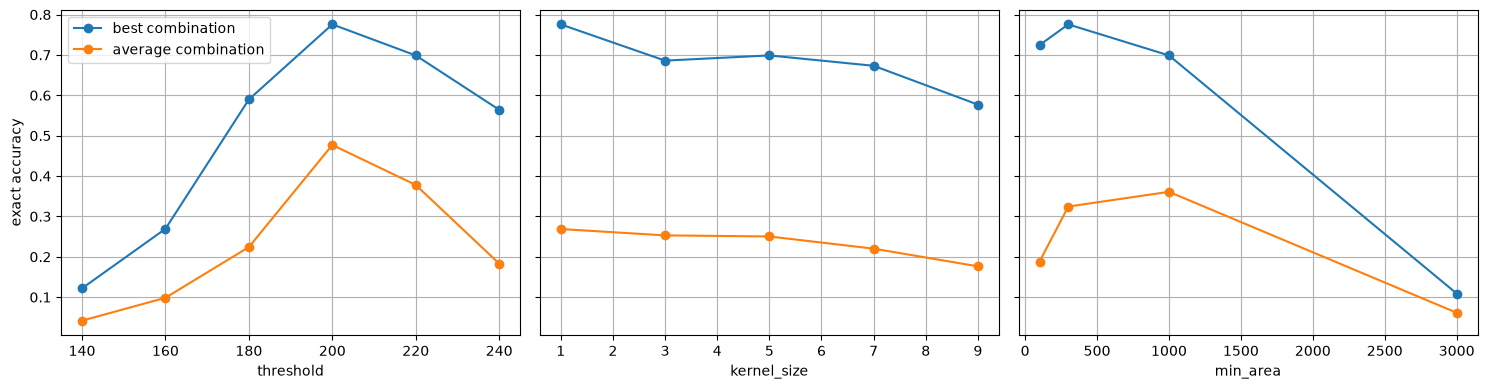

In [8]:
# Effect of each setting on its own: the best and the average accuracy
# over all combinations that use that value
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, setting in zip(axes, SETTINGS):
    best_by_value = summary.groupby(setting)["exact_accuracy"].max()
    mean_by_value = summary.groupby(setting)["exact_accuracy"].mean()

    ax.plot(best_by_value.index, best_by_value.values, marker="o", label="best combination")
    ax.plot(mean_by_value.index, mean_by_value.values, marker="o", label="average combination")
    ax.set_xlabel(setting)
    ax.grid(True)

axes[0].set_ylabel("exact accuracy")
axes[0].legend()
plt.tight_layout()
fig.savefig(FIGURE_DIR / "sweep_settings.png", dpi=150, bbox_inches="tight")
plt.show()

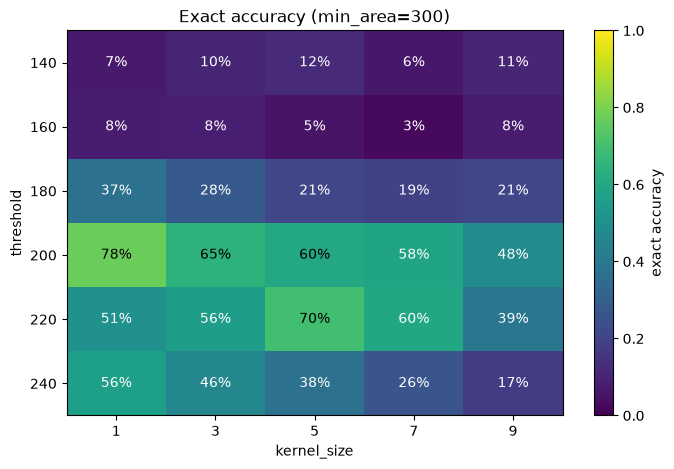

In [9]:
# Threshold against kernel size, with min_area fixed at its best value
grid = summary[summary["min_area"] == best_min_area].pivot(
    index="threshold", columns="kernel_size", values="exact_accuracy"
)

fig, ax = plt.subplots(figsize=(8, 5))
heatmap = ax.imshow(grid.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")

ax.set_xticks(range(len(grid.columns)), labels=grid.columns)
ax.set_yticks(range(len(grid.index)), labels=grid.index)
ax.set_xlabel("kernel_size")
ax.set_ylabel("threshold")
ax.set_title(f"Exact accuracy (min_area={best_min_area})")

for row in range(grid.shape[0]):
    for col in range(grid.shape[1]):
        value = grid.values[row, col]
        ax.text(col, row, f"{value:.0%}", ha="center", va="center",
                color="black" if value > 0.6 else "white")

fig.colorbar(heatmap, label="exact accuracy")
fig.savefig(FIGURE_DIR / "sweep_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### How far off the best setting is

Predicted count minus true count for every image, with the best combination of settings.

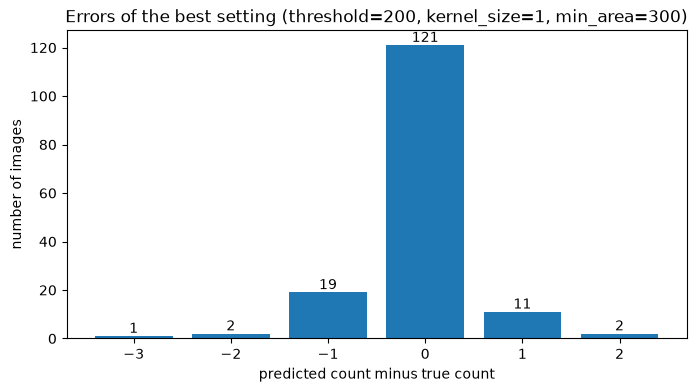

121 of 156 images counted exactly right
30 of the 35 misses are off by one part
22 undercounted, 13 overcounted


In [10]:
best_results = results[
    (results["threshold"] == best_threshold)
    & (results["kernel_size"] == best_kernel_size)
    & (results["min_area"] == best_min_area)
]

error_counts = best_results["error"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(error_counts.index, error_counts.values)
ax.bar_label(bars)
ax.set_xticks(error_counts.index)
ax.set_xlabel("predicted count minus true count")
ax.set_ylabel("number of images")
ax.set_title(f"Errors of the best setting (threshold={best_threshold}, kernel_size={best_kernel_size}, "
             f"min_area={best_min_area})")
fig.savefig(FIGURE_DIR / "error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

wrong = best_results[best_results["error"] != 0]

print(f"{len(best_results) - len(wrong)} of {len(best_results)} images counted exactly right")
print(f"{(wrong['error'].abs() == 1).sum()} of the {len(wrong)} misses are off by one part")
print(f"{(wrong['error'] < 0).sum()} undercounted, {(wrong['error'] > 0).sum()} overcounted")

## 3. Two images in detail

`show_counted_regions` runs the pipeline on one image and draws a red box around every region that was counted as a part. The last view zooms in on those regions and shows the area of each one in pixels.

`count_table` shows the predicted count for one image at every threshold and kernel size in the sweep.

In [11]:
def show_counted_regions(image_number, threshold=200, kernel_size=3, min_area=300, save=False):
    frame = load_image(image_number)
    gray, binary, cleaned, count = run_pipeline(frame, threshold, kernel_size, min_area)

    # Same labeling count_objects does, but keep the box around every region that passes the cutoff
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(cleaned, connectivity=8)
    counted = [stats[i] for i in range(1, num_labels) if stats[i, cv2.CC_STAT_AREA] >= min_area]

    print(f"{num_labels - 1} white regions after closing + opening, "
          f"{len(counted)} passed the area cutoff of {min_area}")

    # Zoom window: the part of the image that holds every counted region, plus a margin.
    # With nothing counted it stays the whole image.
    height, width = cleaned.shape
    left, top, right, bottom = 0, 0, width, height

    if counted:
        margin = 60
        left = max(min(x for x, y, w, h, area in counted) - margin, 0)
        top = max(min(y for x, y, w, h, area in counted) - margin, 0)
        right = min(max(x + w for x, y, w, h, area in counted) + margin, width)
        bottom = min(max(y + h for x, y, w, h, area in counted) + margin, height)

    views = [cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), binary, cleaned, cleaned]
    titles = [
        "Original",
        f"Binary threshold ({threshold})",
        f"Closing + opening ({kernel_size}x{kernel_size} kernel)",
        "Closing + opening, zoomed in on the counted regions",
    ]

    fig, ax = plt.subplots(2, 2, figsize=(14, 8))

    for a, view, title in zip(ax.flat, views, titles):
        a.imshow(view, cmap="gray", vmin=0, vmax=255)
        a.set_title(title)
        a.axis("off")

        for x, y, w, h, area in counted:
            a.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1.5))

    zoomed = ax.flat[3]
    zoomed.set_xlim(left, right)
    zoomed.set_ylim(bottom, top)

    for x, y, w, h, area in counted:
        zoomed.annotate(f"{area} px", (x, y), xytext=(0, 6), textcoords="offset points",
                        color="red", fontsize=9)

    # Yellow box on the full views shows where the zoomed view is
    if counted:
        for a in ax.flat[:3]:
            a.add_patch(Rectangle((left, top), right - left, bottom - top,
                                  fill=False, edgecolor="yellow", linewidth=1, linestyle="--"))

    fig.suptitle(
        f"image ({image_number}).jpg   predicted: {count}   true: {true_counts[image_number - 1]}   "
        f"(threshold={threshold}, kernel_size={kernel_size}, min_area={min_area})"
    )
    plt.tight_layout()

    if save:
        fig.savefig(FIGURE_DIR / f"image_{image_number}_threshold_{threshold}_kernel_{kernel_size}.png",
                    dpi=150, bbox_inches="tight")

    plt.show()


def count_table(image_number, min_area=300):
    # Predicted count for one image at every threshold and kernel size in the sweep
    image_results = results[(results["image"] == image_number) & (results["min_area"] == min_area)]

    print(f"image ({image_number}).jpg   true: {true_counts[image_number - 1]}   "
          f"predicted count with min_area={min_area}:")
    return image_results.pivot(index="threshold", columns="kernel_size", values="predicted")

### Image 156: an empty scene

There are no parts in this image, so the true count is 0.

In [12]:
count_table(156)

image (156).jpg   true: 0   predicted count with min_area=300:


kernel_size,1,3,5,7,9
threshold,,,,,
140,3,3,2,5,6
160,5,6,6,5,4
180,6,5,6,7,6
200,2,3,3,4,6
220,0,0,0,0,0
240,0,0,0,0,0


148 white regions after closing + opening, 2 passed the area cutoff of 300


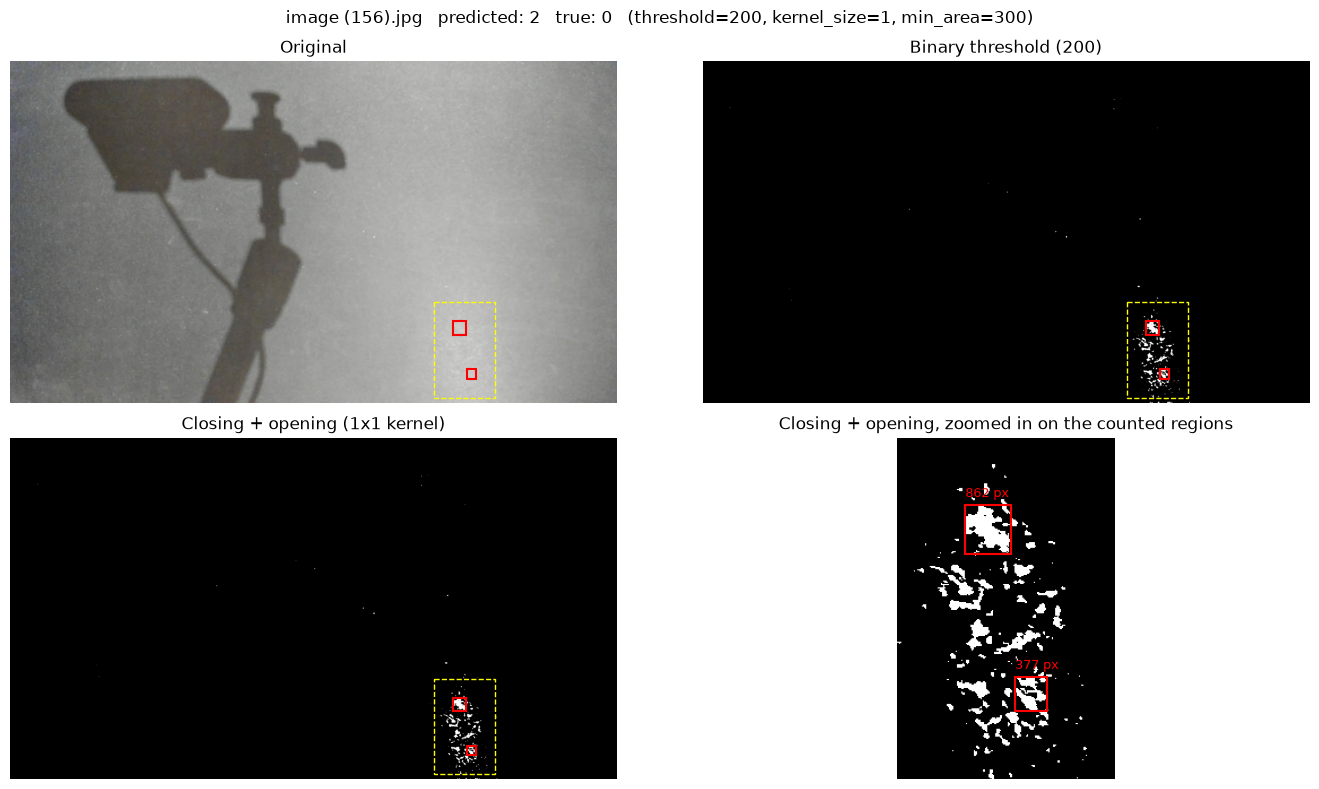

58 white regions after closing + opening, 3 passed the area cutoff of 300


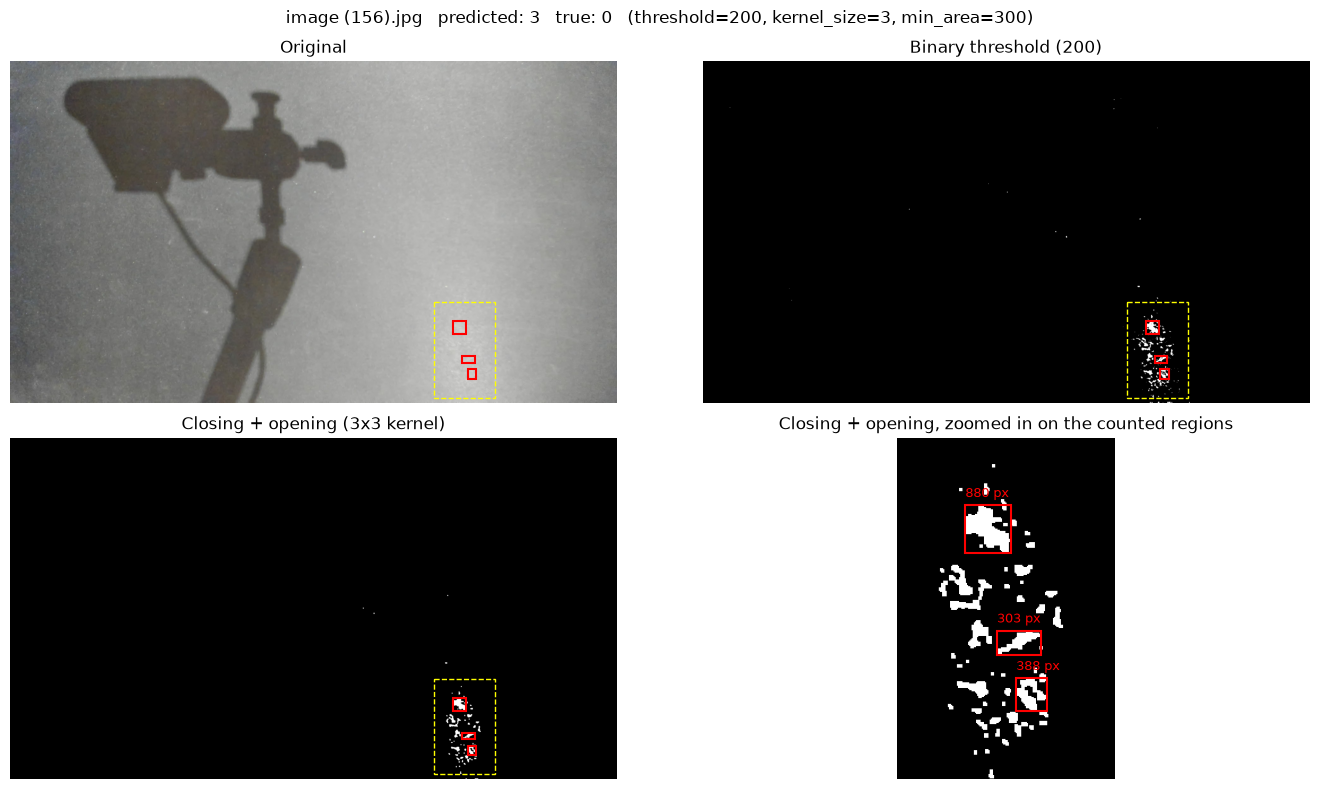

0 white regions after closing + opening, 0 passed the area cutoff of 300


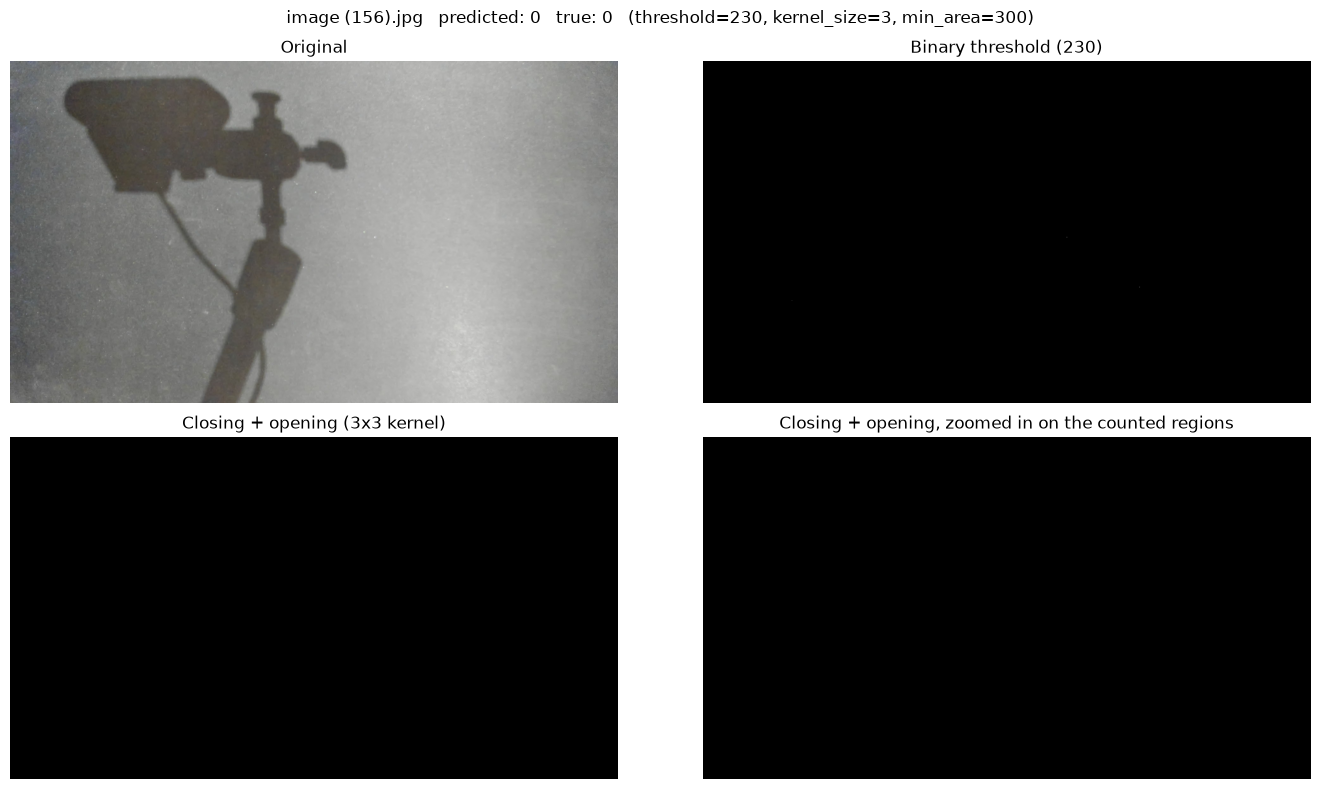

In [13]:
# (threshold, kernel_size) for each figure
for threshold, kernel_size in [(200, 1), (200, 3), (230, 3)]:
    show_counted_regions(156, threshold, kernel_size, min_area=300, save=True)

In [14]:
# Threshold 230 with a 3x3 kernel fixes image 156. Is it a better setting for every image?
# 230 is not one of the thresholds in the sweep, so it is run here.
exact = 0

for number, true_count in enumerate(true_counts, start=1):
    gray, binary, cleaned, count = run_pipeline(load_image(number), threshold=230, kernel_size=3, min_area=300)

    if count == true_count:
        exact += 1

print(f"threshold=230, kernel_size=3, min_area=300: {exact} of {len(true_counts)} images exactly right "
      f"({exact / len(true_counts):.1%})")
print(f"Best setting in the sweep: {summary.loc[0, 'exact_accuracy']:.1%}")

threshold=230, kernel_size=3, min_area=300: 75 of 156 images exactly right (48.1%)
Best setting in the sweep: 77.6%


What image 156 shows:

- **Threshold 200, kernel size 1: 2 parts.** The empty surface is brighter on the right side, just above the threshold of 200. Two of the white regions (862 and 377 pixels) pass the 300 pixel area cutoff.
- **Threshold 200, 3x3 kernel: 3 parts.** Closing runs first and joins nearby specks together, so one more region (303 pixels) passes the cutoff. The table shows that a bigger kernel only makes it worse.
- **Threshold 230, 3x3 kernel: 0 parts.** Only a few pixels in the image are brighter than 230, so there is nothing left to count. But over all 156 images this setting gets 48.1% exactly right, compared to 77.6% for the best setting.

The threshold only looks at brightness, so it cannot tell a bright patch of background from a part.

### Image 29: 15 parts, some of them touching

The true count is 15. Three nuts touch each other in the middle, and two small nuts touch each other below them.

In [15]:
count_table(29)

image (29).jpg   true: 15   predicted count with min_area=300:


kernel_size,1,3,5,7,9
threshold,,,,,
140,11,9,11,8,10
160,19,28,22,22,16
180,17,16,13,13,16
200,14,12,12,12,14
220,15,14,13,12,12
240,15,14,13,13,12


3071 white regions after closing + opening, 17 passed the area cutoff of 300


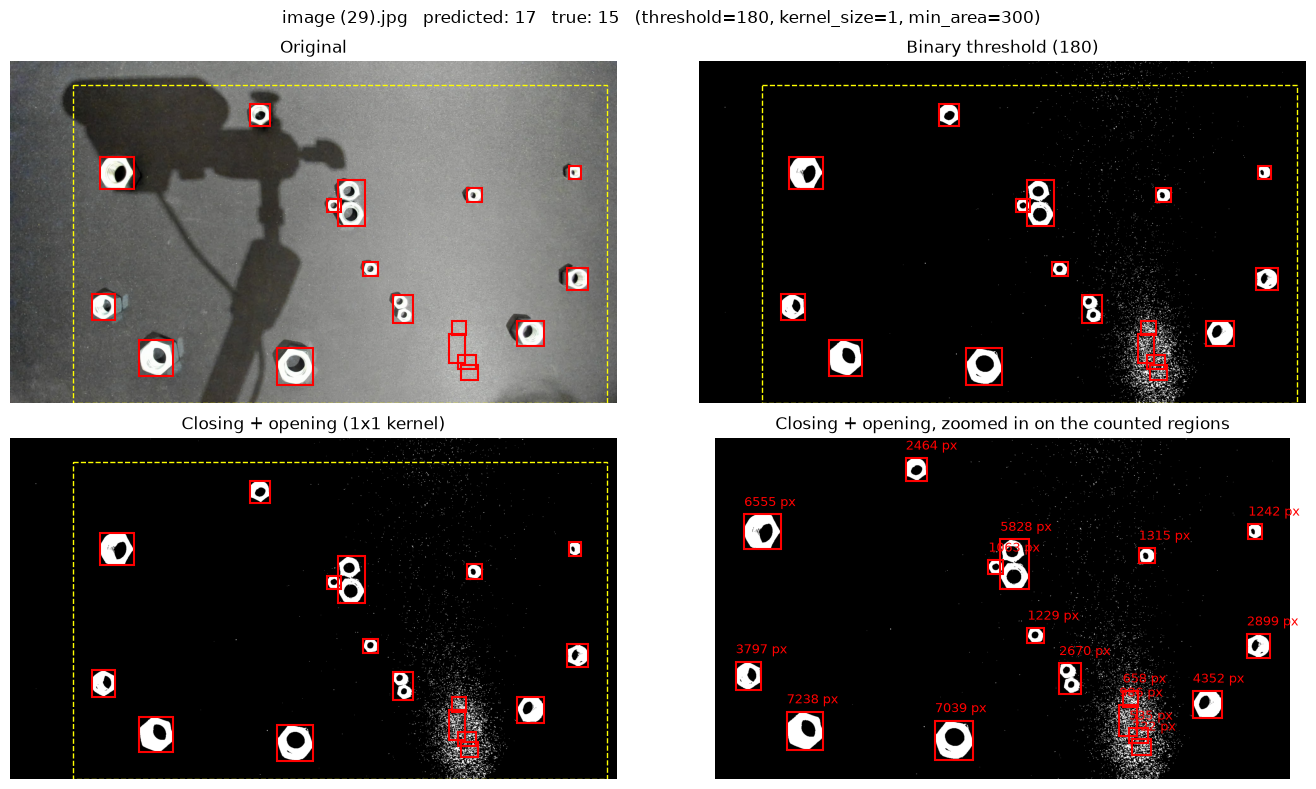

602 white regions after closing + opening, 14 passed the area cutoff of 300


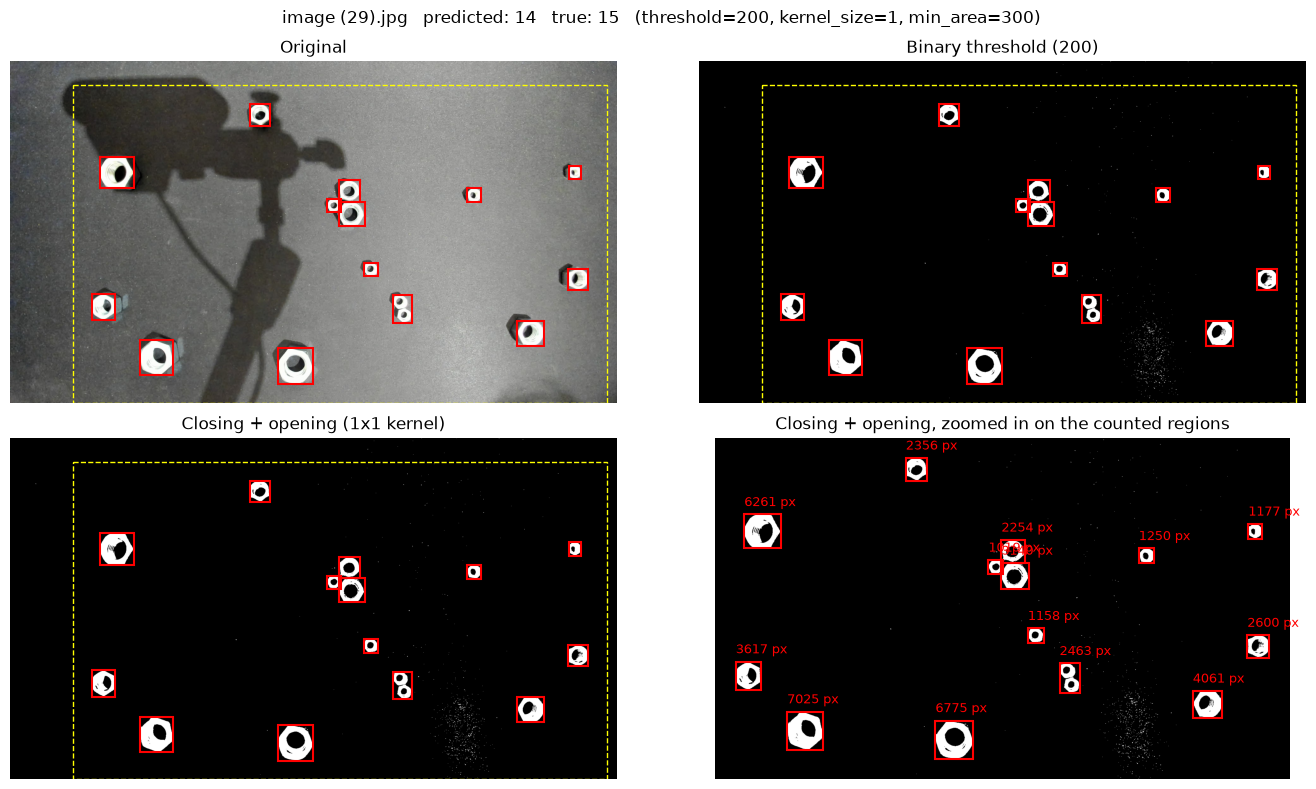

16 white regions after closing + opening, 12 passed the area cutoff of 300


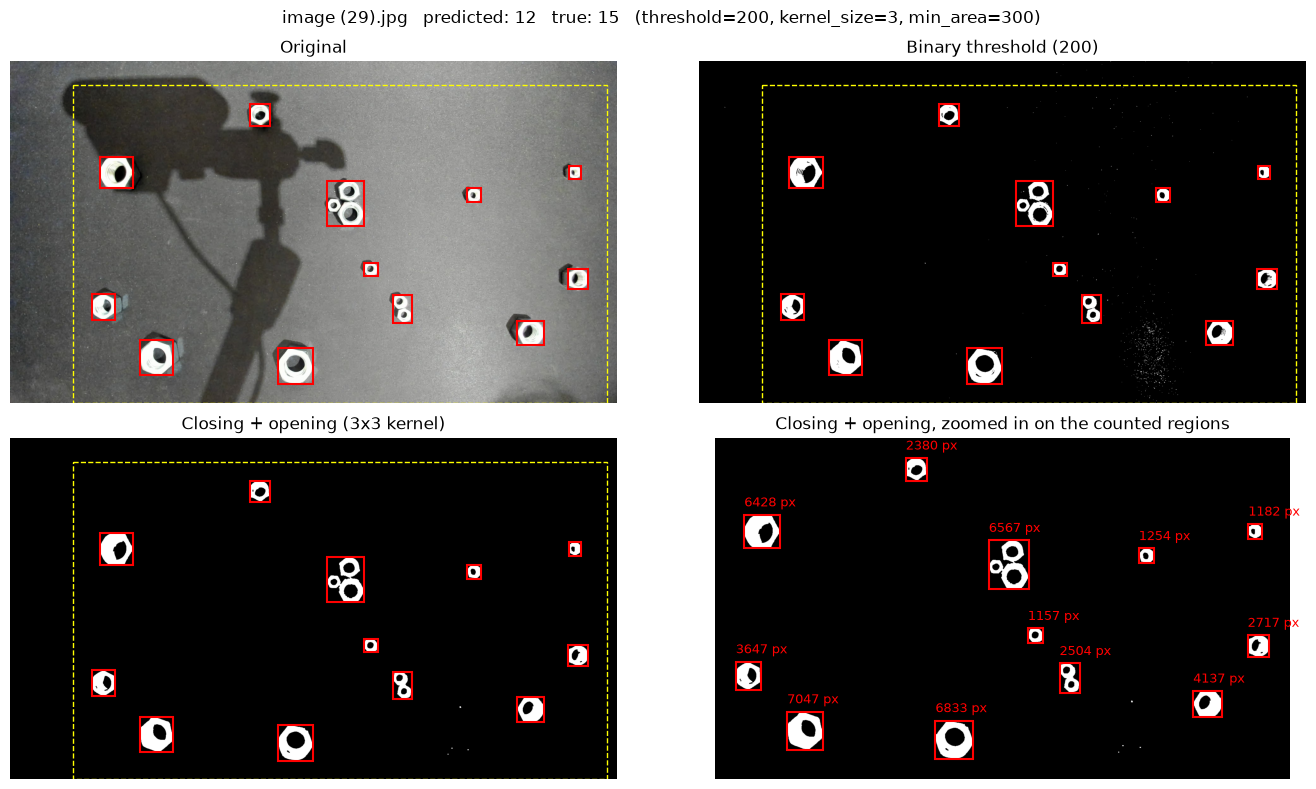

95 white regions after closing + opening, 15 passed the area cutoff of 300


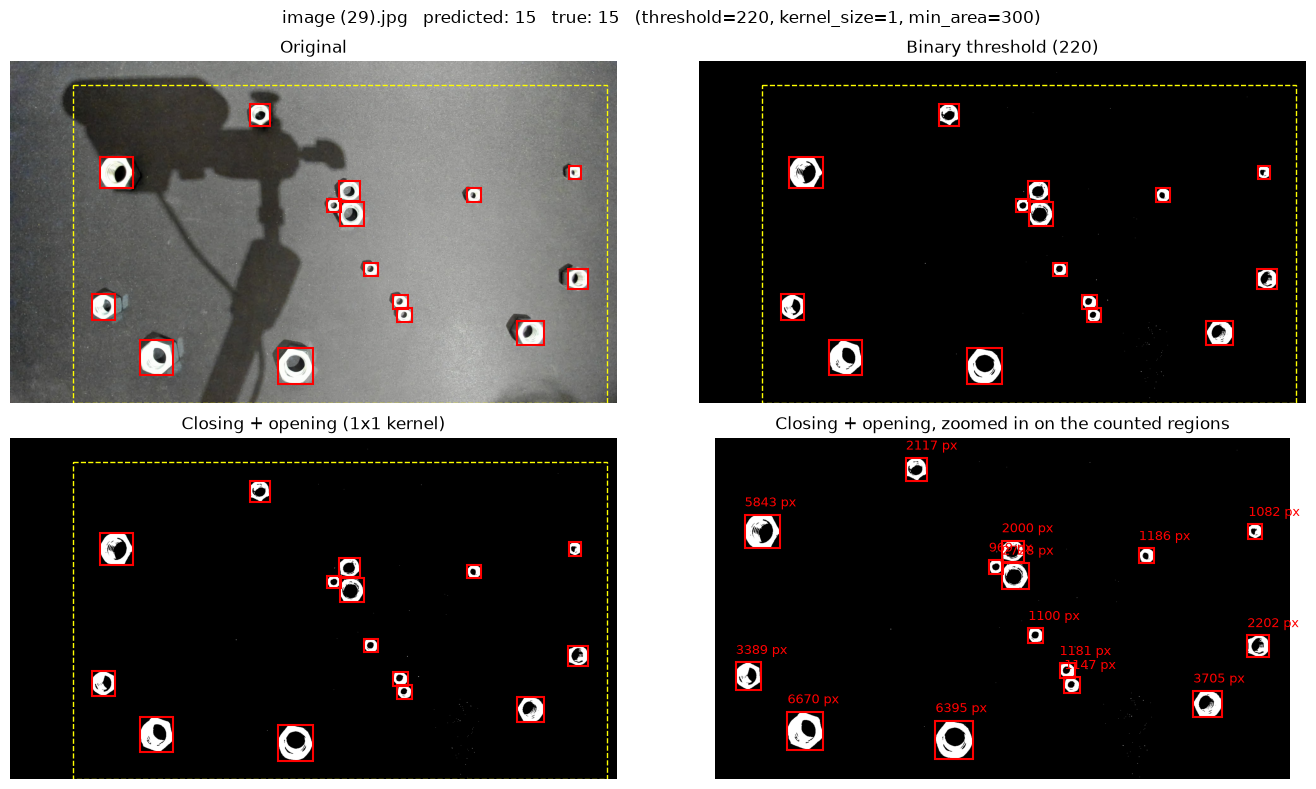

In [16]:
for threshold, kernel_size in [(180, 1), (200, 1), (200, 3), (220, 1)]:
    show_counted_regions(29, threshold, kernel_size, min_area=300, save=True)

What image 29 shows:

- **Threshold 180, kernel size 1: 17 parts.** The threshold is too low. The bright patch at the lower right (the same place as in image 156) adds 4 regions that are not parts, and nuts that touch are joined into one region.
- **Threshold 200, kernel size 1: 14 parts.** This is the best setting from the sweep. The two small nuts that touch are counted as one region.
- **Threshold 200, 3x3 kernel: 12 parts.** Closing also joins the group of three nuts into one region.
- **Threshold 220, kernel size 1: 15 parts.** The touching nuts separate and the count is right.

Connected component labeling counts regions, not parts. When two parts touch they become one region. A higher threshold separates them here only because the pixels where the nuts touch are not as bright as the rest of the nut (above 200 but not above 220).

### Try any image and settings

15 white regions after closing + opening, 12 passed the area cutoff of 300


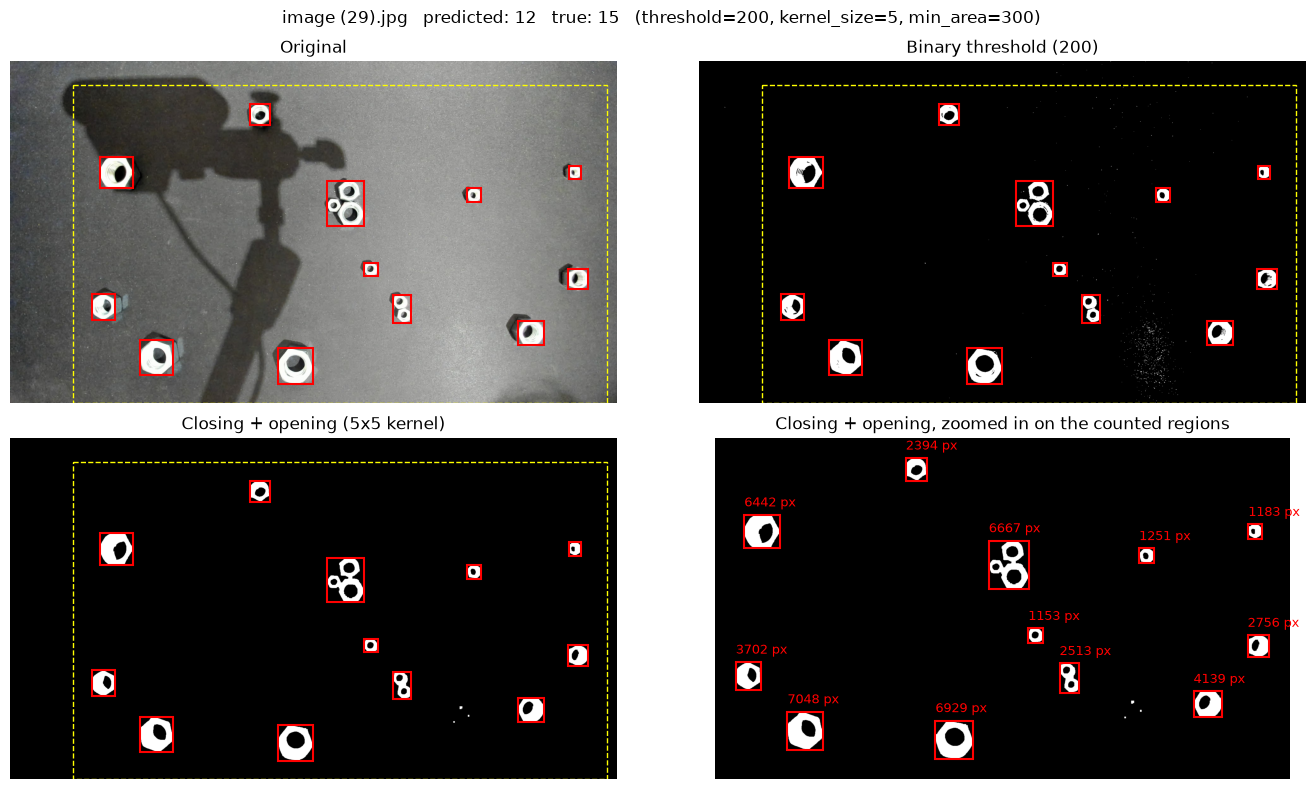

In [17]:
# Change these and re-run this cell
TEST_IMAGE = 29
TEST_THRESHOLD = 200
TEST_KERNEL_SIZE = 5
TEST_MIN_AREA = 300

show_counted_regions(TEST_IMAGE, TEST_THRESHOLD, TEST_KERNEL_SIZE, TEST_MIN_AREA)

## 4. My functions against OpenCV

This compares the functions I wrote in `functions/` against the OpenCV function that does the same job. It looks at two things: whether the output is different, and how long each one takes to run.

| Stage | Mine | OpenCV |
|---|---|---|
| Grayscale | `gray_scale_frame` | `cv2.cvtColor` |
| Thresholding | `binary_threshold` | `cv2.threshold` |
| Closing + opening | `dilate` and `erode` | `cv2.morphologyEx` (inside `morph_operation`) |
| Counting | not written yet | `cv2.connectedComponentsWithStats` (inside `count_objects`) |

Counting uses OpenCV on both sides, because I have not written my own yet. Everything uses the defaults in `functions/`: threshold 200, 3x3 kernel, minimum area 300.

This section only needs the setup cells (imports and dataset). It takes about five minutes to run, because my `dilate` and `erode` loop over every pixel in Python.

In [18]:
COMPARE_THRESHOLD = 200
COMPARE_MIN_AREA = 300
KERNEL = np.ones((3, 3), dtype=np.uint8)   # dilate and erode in functions/ always use a 3x3 kernel


def my_morph_operation(binary_frame):
    closed_img = erode(dilate(binary_frame))    # Closing: dilate, then erode
    return dilate(erode(closed_img))            # Opening: erode, then dilate


def erode_black_border(binary_frame):
    # OpenCV erosion that treats everything outside the image as black, like the zero padding in my erode
    return cv2.erode(binary_frame, KERNEL, borderType=cv2.BORDER_CONSTANT, borderValue=0)


def stand_in_morph_operation(binary_frame):
    # Same steps as my_morph_operation, but with OpenCV functions so it is fast enough for every image
    closed_img = erode_black_border(cv2.dilate(binary_frame, KERNEL))
    return cv2.dilate(erode_black_border(closed_img), KERNEL)


def farthest_from_edge(different):
    # Largest distance, in pixels, from a different pixel to the nearest edge of the image
    rows, columns = np.nonzero(different)

    if len(rows) == 0:
        return "-"

    height, width = different.shape
    return np.minimum.reduce([rows, columns, height - 1 - rows, width - 1 - columns]).max()

### Grayscale and thresholding

Every pixel of all 156 images.

In [19]:
stage_rows = []

for number in range(1, len(true_counts) + 1):
    frame = load_image(number)

    my_gray = gray_scale_frame(frame)
    cv_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray_difference = cv_gray.astype(int) - my_gray.astype(int)

    # The weighted sum before it is turned into a whole number
    weighted_sum = np.dot(frame, weights)

    # Both get the same grayscale image, so only the thresholding is compared
    my_binary = binary_threshold(my_gray, COMPARE_THRESHOLD)
    cv_binary = cv2.threshold(my_gray, COMPARE_THRESHOLD, 255, cv2.THRESH_BINARY)[1]

    stage_rows.append({
        "image": number,
        "gray_identical": (gray_difference == 0).mean(),
        "gray_lowest_difference": gray_difference.min(),
        "gray_highest_difference": gray_difference.max(),
        "mine_is_cut_off": (my_gray == np.floor(weighted_sum)).mean(),
        "opencv_is_rounded": (cv_gray == np.rint(weighted_sum)).mean(),
        "threshold_pixels_different": (my_binary != cv_binary).sum(),
    })

stage_check = pd.DataFrame(stage_rows)

print("Grayscale: gray_scale_frame against cv2.cvtColor")
print(f"  identical pixels in an image: {stage_check['gray_identical'].min():.1%} to "
      f"{stage_check['gray_identical'].max():.1%}, average {stage_check['gray_identical'].mean():.1%}")
print("  OpenCV value minus my value is always from",
      stage_check["gray_lowest_difference"].min(), "to", stage_check["gray_highest_difference"].max())
print(f"  my value is the weighted sum with the decimals cut off: {stage_check['mine_is_cut_off'].min():.2%} of pixels")
print(f"  the OpenCV value is the weighted sum rounded: {stage_check['opencv_is_rounded'].min():.2%} of pixels")

print("Thresholding: binary_threshold against cv2.threshold on the same grayscale image")
print("  images with any different pixel:",
      (stage_check["threshold_pixels_different"] > 0).sum(), "of", len(stage_check))

Grayscale: gray_scale_frame against cv2.cvtColor
  identical pixels in an image: 26.5% to 52.3%, average 38.0%
  OpenCV value minus my value is always from 0 to 1
  my value is the weighted sum with the decimals cut off: 100.00% of pixels
  the OpenCV value is the weighted sum rounded: 100.00% of pixels
Thresholding: binary_threshold against cv2.threshold on the same grayscale image
  images with any different pixel: 0 of 156


### Closing and opening with my dilate and erode

My `dilate` and `erode` loop over every pixel in Python, so each one takes several seconds on a full image. The first cell checks one function at a time on one image. The second runs my closing + opening on a few images.

In [20]:
# Image 81 has the most white pixels touching the edge of the image
edge_binary = binary_threshold(gray_scale_frame(load_image(81)), COMPARE_THRESHOLD)

my_dilated = dilate(edge_binary)
my_eroded = erode(edge_binary)
erode_different = my_eroded != cv2.erode(edge_binary, KERNEL)

print("dilate matches cv2.dilate:", np.array_equal(my_dilated, cv2.dilate(edge_binary, KERNEL)))
print("erode matches cv2.erode:", np.array_equal(my_eroded, cv2.erode(edge_binary, KERNEL)))
print("  pixels different:", erode_different.sum(), "  farthest from the edge:", farthest_from_edge(erode_different))
print("erode matches cv2.erode with a black border:", np.array_equal(my_eroded, erode_black_border(edge_binary)))

dilate matches cv2.dilate: True
erode matches cv2.erode: False
  pixels different: 77   farthest from the edge: 0
erode matches cv2.erode with a black border: True


In [21]:
# About 30 seconds per image. 23 and 81 have the most white on the edge of the image, 70 has none.
COMPARE_IMAGES = [1, 23, 70, 81, 156]

morph_rows = []

for number in COMPARE_IMAGES:
    binary = binary_threshold(gray_scale_frame(load_image(number)), COMPARE_THRESHOLD)

    my_cleaned = my_morph_operation(binary)
    cv_cleaned = morph_operation(binary, 3)
    different = my_cleaned != cv_cleaned

    morph_rows.append({
        "image": number,
        "pixels_different": different.sum(),
        "farthest_from_edge": farthest_from_edge(different),
        "my_count": count_objects(my_cleaned, COMPARE_MIN_AREA),
        "opencv_count": count_objects(cv_cleaned, COMPARE_MIN_AREA),
        "stand_in_matches_mine": np.array_equal(my_cleaned, stand_in_morph_operation(binary)),
    })

pd.DataFrame(morph_rows)

,image,pixels_different,farthest_from_edge,my_count,opencv_count,stand_in_matches_mine
0,1,0,-,17,17,True
1,23,74,2,11,11,True
2,70,0,-,10,10,True
3,81,87,2,20,20,True
4,156,30,1,3,3,True


### Final counts on all 156 images

My closing + opening is too slow to run on every image, so this uses `stand_in_morph_operation` in its place. The table above checks that the stand-in gives exactly the same mask as my functions.

In [22]:
count_rows = []

for number, true_count in enumerate(true_counts, start=1):
    frame = load_image(number)

    # Mine: my grayscale and thresholding, then the stand-in for my dilate and erode
    my_binary = binary_threshold(gray_scale_frame(frame), COMPARE_THRESHOLD)
    my_cleaned = stand_in_morph_operation(my_binary)

    # My grayscale and thresholding, then OpenCV closing + opening (this is what run_pipeline does)
    mixed_cleaned = morph_operation(my_binary, 3)

    # OpenCV for every stage
    cv_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    cv_binary = cv2.threshold(cv_gray, COMPARE_THRESHOLD, 255, cv2.THRESH_BINARY)[1]
    cv_cleaned = morph_operation(cv_binary, 3)

    count_rows.append({
        "image": number,
        "true": true_count,
        "my_count": count_objects(my_cleaned, COMPARE_MIN_AREA),
        "opencv_morphology_count": count_objects(mixed_cleaned, COMPARE_MIN_AREA),
        "all_opencv_count": count_objects(cv_cleaned, COMPARE_MIN_AREA),
        "morphology_pixels_different": (my_cleaned != mixed_cleaned).sum(),
    })

counts = pd.DataFrame(count_rows)

print("Closing + opening, mine against OpenCV on the same binary image")
print("  images with any different pixel:", (counts["morphology_pixels_different"] > 0).sum(), "of", len(counts))
print("  pixels different in all images together:", counts["morphology_pixels_different"].sum())
print("  images where the count changes:", (counts["my_count"] != counts["opencv_morphology_count"]).sum())

print("Whole pipeline, images counted exactly right out of", len(counts))
print("  mine:", (counts["my_count"] == counts["true"]).sum())
print("  OpenCV for every stage:", (counts["all_opencv_count"] == counts["true"]).sum())

print("Images where the two pipelines count differently:")
counts[counts["my_count"] != counts["all_opencv_count"]][["image", "true", "my_count", "all_opencv_count"]]

Closing + opening, mine against OpenCV on the same binary image
  images with any different pixel: 16 of 156
  pixels different in all images together: 704
  images where the count changes: 0
Whole pipeline, images counted exactly right out of 156
  mine: 101
  OpenCV for every stage: 102
Images where the two pipelines count differently:


,image,true,my_count,all_opencv_count
126,127,18,21,20
136,137,13,14,13
155,156,0,3,7


### How long they take

Each function is timed on the same image as the OpenCV function, at two sizes: a full 1920x1080 test image, and the same image shrunk to 640x480, which is the size the live camera script uses. A function is run several times and the fastest run is kept. The times depend on the computer, so the numbers change a little from run to run.

In [23]:
def fastest_time(function, image, repeats):
    # Run the function a few times and keep the fastest run, in milliseconds
    times = []

    for _ in range(repeats):
        start = time.perf_counter()
        function(image)
        times.append(time.perf_counter() - start)

    return min(times) * 1000


def time_stages(frame, size_name, slow_repeats):
    gray = gray_scale_frame(frame)
    binary = binary_threshold(gray, COMPARE_THRESHOLD)

    # (stage, my function, OpenCV function, the image they both get, how many times mine is run)
    stages = [
        ("Grayscale", gray_scale_frame,
         lambda image: cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), frame, 20),
        ("Thresholding", lambda image: binary_threshold(image, COMPARE_THRESHOLD),
         lambda image: cv2.threshold(image, COMPARE_THRESHOLD, 255, cv2.THRESH_BINARY), gray, 20),
        ("Dilation", dilate,
         lambda image: cv2.dilate(image, KERNEL), binary, slow_repeats),
        ("Erosion", erode,
         lambda image: cv2.erode(image, KERNEL), binary, slow_repeats),
        ("Closing + opening", my_morph_operation,
         lambda image: morph_operation(image, 3), binary, slow_repeats),
    ]

    rows = []

    for stage, my_function, cv_function, image, my_repeats in stages:
        my_ms = fastest_time(my_function, image, my_repeats)
        cv_ms = fastest_time(cv_function, image, 20)

        rows.append({"frame": size_name, "stage": stage, "mine_ms": my_ms, "opencv_ms": cv_ms,
                     "times_slower": my_ms / cv_ms})

    return rows


timing_frame = load_image(29)
camera_frame = cv2.resize(timing_frame, (640, 480))   # The size the live camera script uses

# About a minute, almost all of it in my dilate and erode
timing = pd.DataFrame(
    time_stages(timing_frame, "1920x1080 test image", slow_repeats=1)
    + time_stages(camera_frame, "640x480 camera frame", slow_repeats=3)
)

timing.round({"mine_ms": 2, "opencv_ms": 3, "times_slower": 1})

,frame,stage,mine_ms,opencv_ms,times_slower
0,1920x1080 test image,Grayscale,50.40,0.670,75.2
1,1920x1080 test image,Thresholding,3.95,0.520,7.6
2,1920x1080 test image,Dilation,8631.67,0.554,15572.2
3,1920x1080 test image,Erosion,8033.71,0.594,13524.8
4,1920x1080 test image,Closing + opening,31706.30,3.526,8991.1
5,640x480 camera frame,Grayscale,6.39,0.041,154.0
6,640x480 camera frame,Thresholding,0.34,0.011,31.5
7,640x480 camera frame,Dilation,1164.34,0.035,32984.0
8,640x480 camera frame,Erosion,1180.89,0.036,32621.2
9,640x480 camera frame,Closing + opening,4666.84,0.138,33768.7


In [24]:
# One frame through grayscale, thresholding and closing + opening
for size_name, rows in timing.groupby("frame", sort=False):
    whole = rows[rows["stage"].isin(["Grayscale", "Thresholding", "Closing + opening"])]
    my_total = whole["mine_ms"].sum()
    cv_total = whole["opencv_ms"].sum()

    print(size_name)
    print(f"  mine:   {my_total:,.1f} ms per frame = {1000 / my_total:,.2f} frames per second")
    print(f"  OpenCV: {cv_total:,.2f} ms per frame = {1000 / cv_total:,.0f} frames per second")

1920x1080 test image
  mine:   31,760.7 ms per frame = 0.03 frames per second
  OpenCV: 4.72 ms per frame = 212 frames per second
640x480 camera frame
  mine:   4,673.6 ms per frame = 0.21 frames per second
  OpenCV: 0.19 ms per frame = 5,252 frames per second


### What the comparison shows

**Results**

- **Thresholding gives identical results.** No pixel is different in any of the 156 images.
- **Grayscale is off by one for most pixels.** On average only 38.0% of the pixels in an image are identical. For the rest, the OpenCV value is exactly 1 higher. The weighted sum is a decimal number: `astype(np.uint8)` in my function cuts the decimals off, and OpenCV rounds to the nearest whole number.
- **`dilate` gives identical results, `erode` does not.** My `erode` pads the image with black, so white pixels on the edge of the image get eroded. OpenCV does not let anything outside the image affect the result. With a black border OpenCV gives exactly what my `erode` gives.
- **The `erode` difference stays at the edge of the image.** After closing + opening it is at most 2 pixels from the edge in the images tested. It shows up in 16 of 156 images, 704 pixels in total, and it does not change the count in any image.
- **The grayscale difference changes the final count in 3 images** (127, 137 and 156). A pixel with a weighted sum from 200.5 up to 201 becomes 200 in mine and 201 in OpenCV, so only OpenCV puts it above the threshold of 200. Overall my pipeline counts 101 of 156 images exactly right and the all-OpenCV pipeline counts 102.

**Speed** (the exact times change a little from run to run)

- **My NumPy functions are slower than OpenCV, but still fast.** On a 640x480 camera frame, grayscale takes about 6 milliseconds and thresholding less than 1. OpenCV is roughly 150 and 30 times faster, but both of mine fit easily in the 33 milliseconds a frame gets at 30 frames per second.
- **The Python loops are the slow part.** `dilate` and `erode` each take about 1.2 seconds on a camera frame and about 8 seconds on a full test image, more than ten thousand times slower than OpenCV. They visit every pixel one at a time in Python, while grayscale and thresholding do the whole image in one NumPy operation.
- **One camera frame through my functions takes about 4.7 seconds** (grayscale, thresholding, closing + opening), which is about 0.2 frames per second. OpenCV does the same steps in about 0.2 milliseconds. The live camera could not run on my `dilate` and `erode` the way they are written.